In [10]:
import sys
import os

sys.path.append('..')

import warnings

import numpy as np
import pandas as pd

from BPASS_Grid_Fit import BPASSGrid as bpg
from BPASS_Grid_Fit import Target as tgt
from BPASS_Grid_Fit import GridFit as gf

In [2]:
# specify the full grid parameters that you want to generate a fits file for
# full parameter range is given in ../BPASS_Grid/README.txt

# full grid params

# metallicity
Z = [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 4e-3, 6e-3, 8e-3, 1e-2, 1.4e-2, 1.7e-2, 2e-2, 3e-2, 4e-2]
# ionization parameter (given as log10(U))
U = [-4.0, -3.5, -3.0, -2.5, -2.0, -1.5, -1.0]
# dust to metal ratio
xsi = [0.3]
# gas density (given as log10(n_H/cm^-3))        
n_H = [3.0]
# C/O ratio
CO = [0.044]
# define the ages to integrate over in the fits file (in years)
age = [10**(6+0.1*(x-2)) for x in range(2, 23)]
ages = [f'{y:.2e}' for y in age]

# note the column definitions for the hdf5 file datasets

# grid_07_2025.hdf5 contains the following columns for each model:
columns=['Z', 'ha', 'hb', 'o1_6300', 'o2_3727', 'o3_1666', 'o3_4959', 'o3_5007','s2_6716_6731', 'n2_6548', 'n2_6584', 'n5_1243', 'he1_3965', 'he1_4471', 'he1_5876', 'he1_6678', 'he2_1640', 'he2_4686', 'c3_1909', 'c4_1551', 'si3_1892', 'he1_1083', 'n_H']
# grid_07_2025_solar.hdf5 contains the following columns for each model:
#columns=['Z', 'ha', 'hb', 'o1_6300', 'o2_3727', 'o3_1666', 'o3_4959', 'o3_5007','s2_6716_6731', 'n2_6548', 'n2_6584', 'n5_1243', 'he1_3965', 'he1_4471', 'he1_5876', 'he1_6678', 'he2_1640', 'he2_4686', 'c3_1909', 'c4_1551', 'si3_1892', 'he1_1083', 'n_H', 'hg', 'hd', 'o3_4363', 'ne3_3868', 'ar4_4711']

params = {
            'Z': Z,
            'U': U,
            'xsi': xsi,
            'nH': n_H,
            'CO': CO,
            'age': age
         }


In [3]:
# define a version number for the fits file to be generated
v = 1

In [4]:
# define the lines to be included in the fits file
lines = ['HB', 'OIII4959', 'OIII5007', 'OII3727', 'HA', 'SII6716', 'SII6731', 'NII6584', 'NII6548']

In [5]:
grid = bpg.Grid(
                name=f'BPASS_grid_v{v}',
                pars=['LOGZ', 'LOGU'],
                lines=lines,
                fix=None,
                path=f'./BPASS_grid_v{v}.fits',
                recalculate=False
                )

Adding a logarithmic quantity Log_HB
Adding a logarithmic quantity Log_OIII4959
Adding a logarithmic quantity Log_OIII5007
Adding a logarithmic quantity Log_OII3727
Adding a logarithmic quantity Log_HA
Adding a logarithmic quantity Log_SII6716
Adding a logarithmic quantity Log_SII6731
Adding a logarithmic quantity Log_NII6584
Adding a logarithmic quantity Log_NII6548


In [6]:
# Give flux values for the target object
# These are the values that will be used to determine log(U) and log(Z) for the target object
# Example values are given below, but you should replace them with your own values

data = {
        'o3_4959': 507.06,
        'o3_5007': 1673.32,
        'o2_3727': 287.27,
        'ha': 631.49,
        'hb': 249.98,
        's2_6716': 24.42,
        's2_6731': 5.57,
        'n2_6584': 17.20,
        'n2_6548': 5.85
        }
errors = {
        'o3_4959_err': 25.35,
        'o3_5007_err': 83.67,
        'o2_3727_err': 14.36,
        'ha_err': 31.57,
        'hb_err': 12.50,
        's2_6716_err': 1.22,
        's2_6731_err': 0.28,
        'n2_6584_err': 0.86,
        'n2_6548_err': 0.29
        }

combined_data = {**data, **errors}
combined_data['ID'] = [0]

df = pd.DataFrame(combined_data, index=[0])

df

,o3_4959,o3_5007,o2_3727,ha,hb,s2_6716,s2_6731,n2_6584,n2_6548,o3_4959_err,o3_5007_err,o2_3727_err,ha_err,hb_err,s2_6716_err,s2_6731_err,n2_6584_err,n2_6548_err,ID
0,507.06,1673.32,287.27,631.49,249.98,24.42,5.57,17.2,5.85,25.35,83.67,14.36,31.57,12.5,1.22,0.28,0.86,0.29,0


In [7]:
# define a path to save the output files
save_path = './'

# define what lines to use for the fitting process (grid and fluxes must have the same lines)
lines = lines
ls = list(data.keys())

# initialize the target object with the flux values and errors
# we pass the dataframe, the lines to be used for fitting, and a signal-to-noise ratio threshold
target = tgt.Target(
                    id=0,
                    df=df,
                    lines=ls,
                    snr=3
                    )

/Users/lpless/Library/CloudStorage/OneDrive-SwinburneUniversity/PhD/software/BPASS_Grid/examples/../BPASS_Grid_Fit/Target.py:97: UserWarning: Line s2_6716 is a blend of SII lines commonly unresolved. The fluxes will be summed for the SII doublet at 6718 and 6733 A. If you did not mean to do this, please check your input.
  w.warn(f"Line {l} is a blend of SII lines commonly unresolved. The fluxes will be summed for the SII doublet at 6718 and 6733 A. If you did not mean to do this, please check your input.")


/Users/lpless/Library/CloudStorage/OneDrive-SwinburneUniversity/PhD/software/BPASS_Grid/examples/../BPASS_Grid_Fit/GridFit.py:66: UserWarning: The order of the lines to fit does not match the order of the lines in the target object. Please check the input lines. The lines to fit are: ['HB', 'OIII4959', 'OIII5007', 'OII3727', 'HA', 'SII6716', 'SII6731', 'NII6584', 'NII6548'] The lines in the target object are: ['OIII4959', 'OIII5007', 'OII3727', 'HA', 'HB', 'SII6716', 'SII6731', 'NII6584', 'NII6548']
  w.warn("The order of the lines to fit does not match the order of the lines in the target object. Please check the input lines. The lines to fit are: {}".format(self.lines) + " The lines in the target object are: {}".format(self.target.lines))


We have a total of 2 parameters:
   0: LOGZ
   1: LOGU
N_PARAMETERS=2

 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    2
 *****************************************************
I need to linearly interpolate HB - this will take some time!
I need to linearly interpolate OIII4959 - this will take some time!
I need to linearly interpolate OIII5007 - this will take some time!
I need to linearly interpolate OII3727 - this will take some time!
I need to linearly interpolate HA - this will take some time!
I need to linearly interpolate SII6716 - this will take some time!
I need to linearly interpolate SII6731 - this will take some time!
I need to linearly interpolate NII6584 - this will take some time!
I need to linearly interpolate NII6548 - this will take some time!
 ln(ev)=  -808.28208388531425      +/-  0.14679953237891435     
 Total Likelihood Evaluations:     

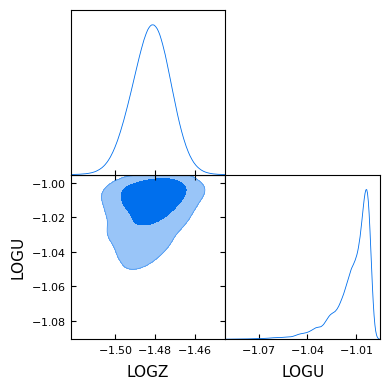

In [9]:
# now run the fit
# we pass the target object, the grid object, the lines to be used for fitting, the path to save the output files, the version number, and a sensitivity parameter that determines how sensitive the matching between the target labels and the grid labels is
fit = gf.Fit(
            target=target,
            model=grid,
            lines=lines,
            path=save_path,
            version=v,
            sensitivity=0.6,
            )

if target.lines != []:
    fit.run_fit()
    fit.show_corner()
    fit.save_results()
else:
    warnings.warn(f'Target {target.id} has no lines with SNR above the threshold. No fit was performed.', UserWarning)